<a href="https://colab.research.google.com/github/dimon22487-dev/---/blob/main/%D0%BF%D1%80%D0%BE%D0%B5%D0%BA%D1%82_%D0%BE%D0%B1%D0%BD%D0%B0%D1%80%D1%83%D0%B6%D0%B5%D0%BD%D0%B8%D0%B5_%D1%82%D0%B5%D0%BB%D0%B5%D1%84%D0%BE%D0%BD%D0%B0_%D0%BF%D0%BE%D1%81%D0%BB%D0%B5%D0%B4%D0%BD%D1%8F%D1%8F%D0%BA%D1%82.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Подготовка среды

In [21]:
# Установка необходимых библиотек
!pip install ultralytics roboflow pandas matplotlib opencv-python -q

# Импорт библиотек
from ultralytics import YOLO
from roboflow import Roboflow
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import glob
import shutil

#Использование предобученной модели
Загрузка изображения и предсказание

In [22]:
!curl -o "orig.jpg" "https://i.pinimg.com/originals/a5/e7/6a/a5e76a8d35f392570a4610a7fa629273.jpg"

!curl -o "origi.jpg" "https://get.pxhere.com/photo/iphone-smartphone-hand-technology-phone-telephone-gadget-mobile-phone-product-google-android-nexus-apps-electronic-device-portable-communications-device-communication-device-feature-phone-554582.jpg"

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 57136  100 57136    0     0   671k      0 --:--:-- --:--:-- --:--:--  672k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 1943k  100 1943k    0     0  8431k      0 --:--:-- --:--:-- --:--:-- 8450k


In [23]:
print("\n--- ЧАСТЬ A: Предобученная модель ---")

# Используем yolo11n.
MODEL_NAME_PRETRAINED = "yolo11n.pt"
model_pretrained = YOLO(MODEL_NAME_PRETRAINED)

img_url = "https://www.infpol.ru/upload/iblock/590/yxsx7emt0tqd1hw5z6jwaotfishsratv.jpg"
image_path = "test.jpg"

if not os.path.exists(image_path):
    !wget -O "$image_path" "$img_url"

results = model_pretrained(image_path)
result = results[0]

print("--- Результаты детекции (Cat & Dog) ---")
for box in result.boxes:
    class_id = int(box.cls[0].item())
    class_name = result.names[class_id]
    coords = [round(x, 2) for x in box.xyxy[0].tolist()]
    confidence = round(box.conf[0].item(), 2)

    print(f"Объект: {class_name}")
    print(f"Координаты: {coords}")
    print(f"Уверенность: {confidence}")
    print("-" * 20)


--- ЧАСТЬ A: Предобученная модель ---

image 1/1 /content/test.jpg: 448x640 1 cup, 1 bowl, 1 dining table, 1 cell phone, 8.2ms
Speed: 1.9ms preprocess, 8.2ms inference, 1.2ms postprocess per image at shape (1, 3, 448, 640)
--- Результаты детекции (Cat & Dog) ---
Объект: cell phone
Координаты: [72.97, 97.73, 312.92, 445.56]
Уверенность: 0.92
--------------------
Объект: dining table
Координаты: [9.4, 2.05, 797.89, 545.57]
Уверенность: 0.63
--------------------
Объект: bowl
Координаты: [454.72, 290.17, 696.79, 523.83]
Уверенность: 0.32
--------------------
Объект: cup
Координаты: [399.99, 286.93, 698.61, 526.25]
Уверенность: 0.27
--------------------


Графическое отображение результата

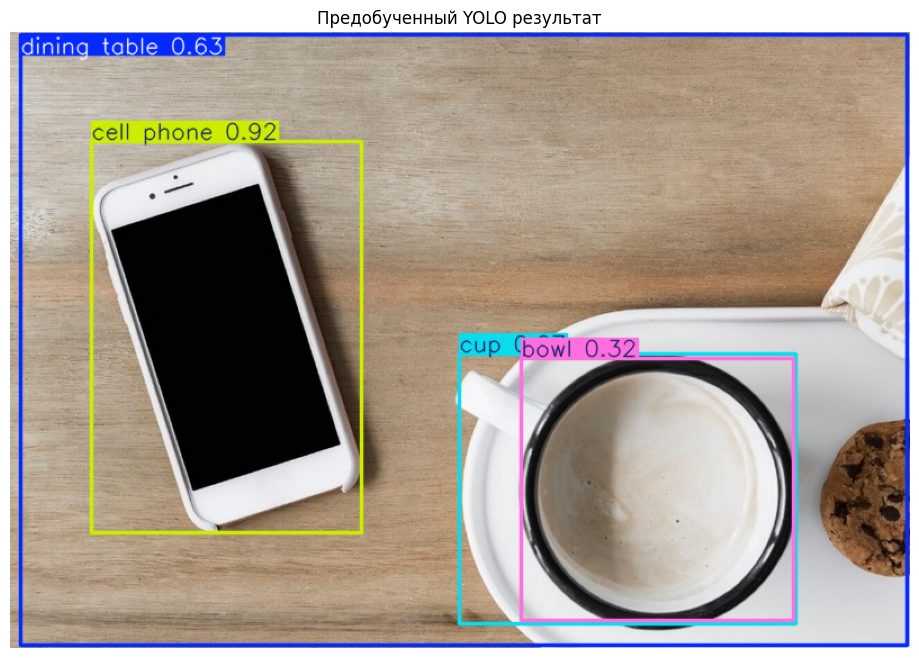

In [24]:
# Визуализация
plotted_img = result.plot()
plotted_img_rgb = cv2.cvtColor(plotted_img, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(12, 8))
plt.imshow(plotted_img_rgb)
plt.axis('off')
plt.title("Предобученный YOLO результат")
plt.show()

#Работа с сервисом Roboflow
Загрузка датасета Roboflow

In [25]:
API_KEY = "asXIgfnGzIZ0WwiXurkN"
WORKSPACE_NAME = "s-workspace-buqcu"
PROJECT_NAME = "phone-t0ls6-wjwef"
VERSION_NUMBER = 1

rf = Roboflow(api_key=API_KEY)
workspace = rf.workspace(WORKSPACE_NAME)
project = workspace.project(PROJECT_NAME)
version = project.version(VERSION_NUMBER)

# Скачиваем датасет в формате yolov8 (совместим с YOLO11)
dataset = version.download("yolov8")
print(f"Датасет скачан в: {dataset.location}")

loading Roboflow workspace...
loading Roboflow project...
Датасет скачан в: /content/phone-1


Сохранение лично аннотированных изображений

In [26]:
# Сохранение личных аннотаций (копируем из train папки скачанного датасета)
os.makedirs("manual_annotations", exist_ok=True)
source_dir = os.path.join(dataset.location, "train/images")

if os.path.exists(source_dir):
    files = os.listdir(source_dir)
    count = min(len(files), 10)
    for img_file in files[:count]:
        src = os.path.join(source_dir, img_file)
        dst = os.path.join("manual_annotations", img_file)
        shutil.copy(src, dst)
    print(f"{count} изображений скопировано в manual_annotations")
else:
    print("Папка с изображениями не найдена.")

10 изображений скопировано в manual_annotations


#Обучение модели
Проведение обучения

In [27]:
print("\n--- ЧАСТЬ C: Обучение модели ---")

data_yaml_path = os.path.join(dataset.location, "data.yaml")

if not os.path.exists(data_yaml_path):
    raise FileNotFoundError(f"Файл data.yaml не найден по пути: {data_yaml_path}")

# Инициализация модели
model_train = YOLO("yolo11n.pt")

# Обучение
results_train = model_train.train(
    data=data_yaml_path,
    epochs=20,      # 20+ эпох для хорошего результата
    imgsz=640,
    batch=16,
    save=True,
    plots=True,
    verbose=False
)

print("Обучение завершено.")


--- ЧАСТЬ C: Обучение модели ---
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/phone-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, op

График изменения точности

Используется папка обучения: runs/detect/train-2


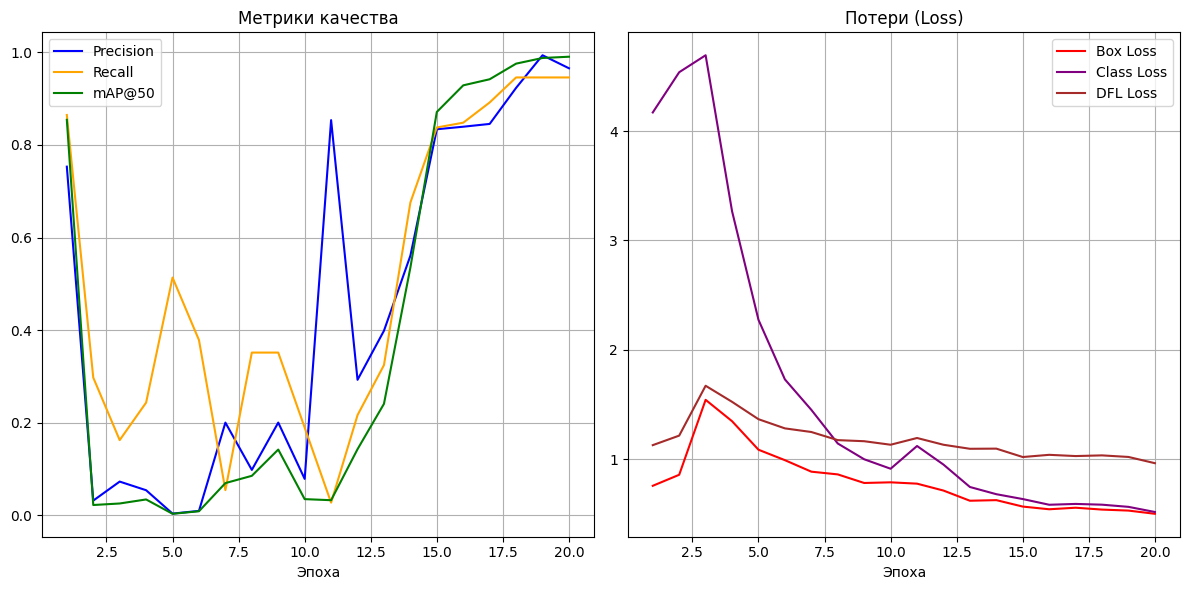

In [28]:
# Поиск последней папки с обучением
train_folders = glob.glob('runs/detect/train*')
if not train_folders:
    raise FileNotFoundError("Папки с обучением не найдены. Запустите обучение заново.")

# Выбираем самую свежую папку
latest_train_folder = max(train_folders, key=os.path.getctime)
best_model_path = os.path.join(latest_train_folder, "weights", "best.pt")
metrics_csv = os.path.join(latest_train_folder, "results.csv")

print(f"Используется папка обучения: {latest_train_folder}")

# Построение графиков
if os.path.exists(metrics_csv):
    df_metrics = pd.read_csv(metrics_csv)

    plt.figure(figsize=(12, 6))

    # Метрики
    plt.subplot(1, 2, 1)
    cols_to_plot = ['metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)']
    colors = ['blue', 'orange', 'green']
    labels = ['Precision', 'Recall', 'mAP@50']

    for col, color, label in zip(cols_to_plot, colors, labels):
        if col in df_metrics.columns:
            plt.plot(df_metrics['epoch'], df_metrics[col], label=label, color=color)

    plt.title('Метрики качества')
    plt.xlabel('Эпоха')
    plt.legend()
    plt.grid(True)

    # Потери
    plt.subplot(1, 2, 2)
    loss_cols = ['train/box_loss', 'train/cls_loss', 'train/dfl_loss']
    loss_labels = ['Box Loss', 'Class Loss', 'DFL Loss']
    loss_colors = ['red', 'purple', 'brown']

    for col, color, label in zip(loss_cols, loss_colors, loss_labels):
        if col in df_metrics.columns:
            plt.plot(df_metrics['epoch'], df_metrics[col], label=label, color=color)

    plt.title('Потери (Loss)')
    plt.xlabel('Эпоха')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()
else:
    print(" Файл metrics не найден.")

Выгрузка лучшей модели

In [29]:
# Экспорт модели
print(f"Лучшая модель: {best_model_path}")

try:
    model_export = YOLO(best_model_path)
    model_export.export(format="onnx", imgsz=640)
    print("Модель экспортирована в ONNX.")
except Exception as e:
    print(f"Ошибка экспорта: {e}")

Лучшая модель: runs/detect/train-2/weights/best.pt
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from 'runs/detect/train-2/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 1.5s, saved as 'runs/detect/train-2/weights/best.onnx' (10.2 MB)

Export complete (1.7s)
Results saved to /content/runs/detect/train-2/weights/best.onnx
Predict:         yolo predict task=detect model=runs/detect/train-2/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=runs/detect/train-2/weights/best.onnx imgsz=640 data=/content/phone-1/data.yaml  
Visualize:       https://netron.app
Модель экспортирована в ONNX.


Предсказание на 5 изображениях с визуализацией


--- Тестирование на 5 изображениях ---

>>> Изображение 1: phone-117-_jpg.rf.128b085a197390396f2fb0573065a68d.jpg

image 1/1 /content/phone-1/test/images/phone-117-_jpg.rf.128b085a197390396f2fb0573065a68d.jpg: 640x640 2 phones, 10.8ms
Speed: 2.1ms preprocess, 10.8ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)


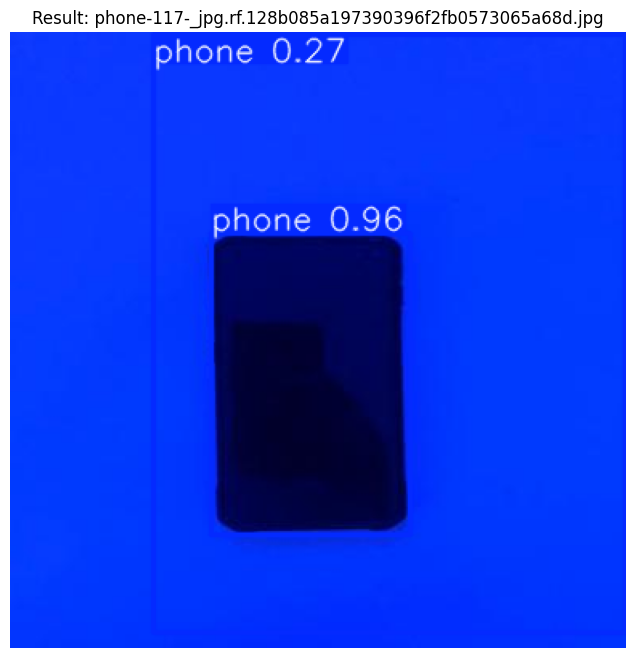

  Объект: phone, Коорд: [125.13, 125.43, 249.58, 313.29], Уверенность: 0.96
  Объект: phone, Коорд: [89.32, 1.48, 383.53, 374.77], Уверенность: 0.27

>>> Изображение 2: phone-46-_jpg.rf.9f855b5a1be63d5461d5e7d0cc1b1bc8.jpg

image 1/1 /content/phone-1/test/images/phone-46-_jpg.rf.9f855b5a1be63d5461d5e7d0cc1b1bc8.jpg: 640x640 2 phones, 12.5ms
Speed: 2.5ms preprocess, 12.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


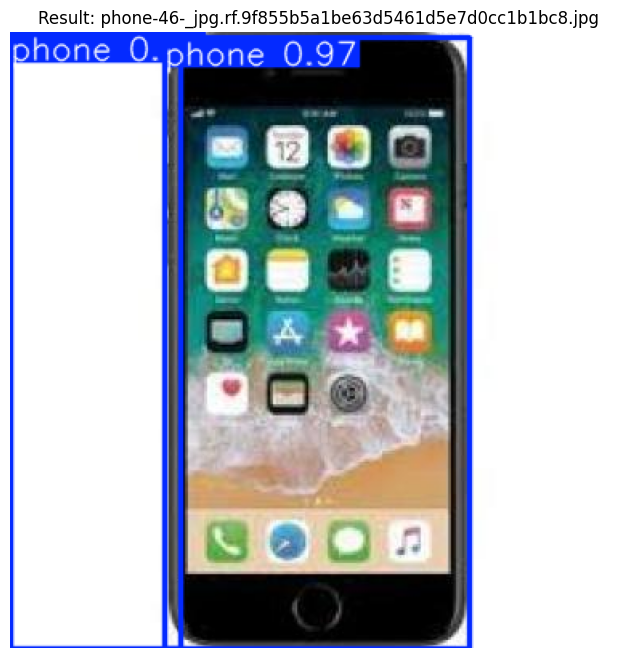

  Объект: phone, Коорд: [96.92, 3.46, 286.21, 384.0], Уверенность: 0.97
  Объект: phone, Коорд: [0.17, 0.0, 106.59, 384.0], Уверенность: 0.14

>>> Изображение 3: phone-131-_jpg.rf.4114813e2bb8568da06ac1b9e1988f3e.jpg

image 1/1 /content/phone-1/test/images/phone-131-_jpg.rf.4114813e2bb8568da06ac1b9e1988f3e.jpg: 640x640 1 phone, 12.5ms
Speed: 2.9ms preprocess, 12.5ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)


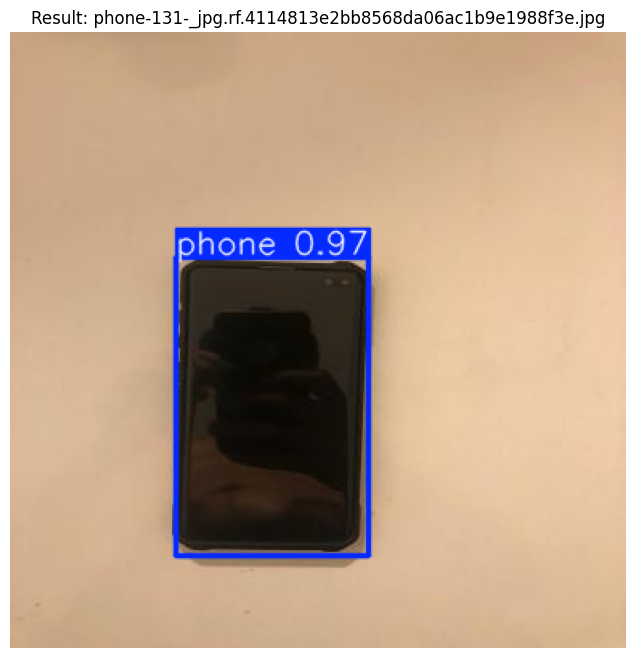

  Объект: phone, Коорд: [103.51, 140.29, 223.07, 326.63], Уверенность: 0.97

>>> Изображение 4: phone-176-_jpg.rf.2d8acb737ba4f127cba03cd03ed38908.jpg

image 1/1 /content/phone-1/test/images/phone-176-_jpg.rf.2d8acb737ba4f127cba03cd03ed38908.jpg: 640x640 2 phones, 12.8ms
Speed: 3.4ms preprocess, 12.8ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 640)


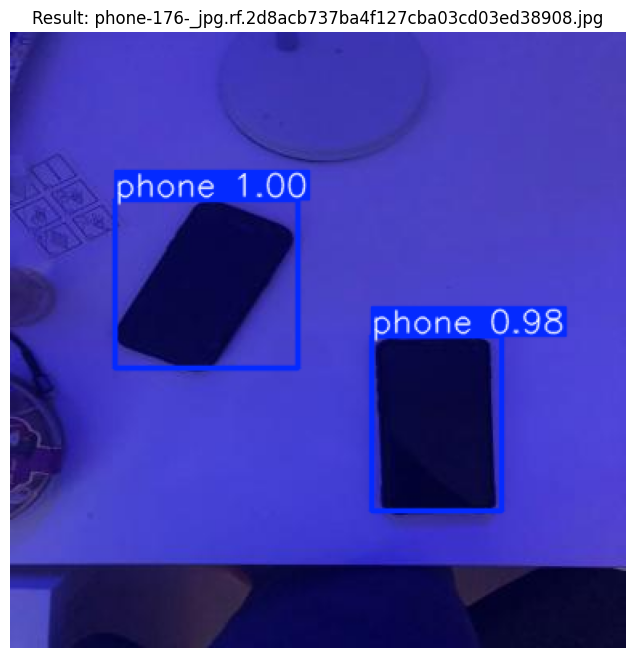

  Объект: phone, Коорд: [65.06, 104.42, 179.35, 209.51], Уверенность: 1.0
  Объект: phone, Коорд: [225.04, 189.43, 306.75, 298.92], Уверенность: 0.98

>>> Изображение 5: phone-74-_jpg.rf.35c1d143c66a3d4ce457a4438d4467b0.jpg

image 1/1 /content/phone-1/test/images/phone-74-_jpg.rf.35c1d143c66a3d4ce457a4438d4467b0.jpg: 640x640 3 phones, 15.1ms
Speed: 3.0ms preprocess, 15.1ms inference, 2.5ms postprocess per image at shape (1, 3, 640, 640)


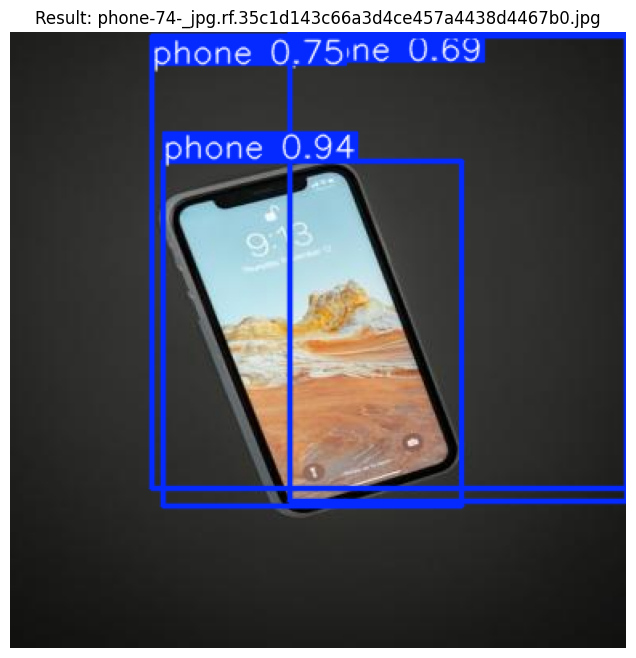

  Объект: phone, Коорд: [95.42, 80.84, 281.66, 295.25], Уверенность: 0.94
  Объект: phone, Коорд: [88.87, 2.05, 384.0, 284.34], Уверенность: 0.75
  Объект: phone, Коорд: [174.72, 0.83, 384.0, 292.72], Уверенность: 0.69


In [30]:
# Тестирование на 5 изображениях
print("\n--- Тестирование на 5 изображениях ---")
best_model = YOLO(best_model_path)

# Пути к тестовым изображениям (берем из актуального dataset)
test_dir = os.path.join(dataset.location, "test/images")
if not os.path.exists(test_dir):
    test_dir = os.path.join(dataset.location, "train/images")

test_images = glob.glob(os.path.join(test_dir, "*.jpg")) + \
              glob.glob(os.path.join(test_dir, "*.jpeg")) + \
              glob.glob(os.path.join(test_dir, "*.png"))

selected_images = test_images[:5]

if selected_images:
    for i, img_path in enumerate(selected_images):
        print(f"\n>>> Изображение {i+1}: {os.path.basename(img_path)}")

        res = best_model(img_path, conf=0.1)[0]
        plotted = res.plot()
        plotted_rgb = cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(10, 8))
        plt.imshow(plotted_rgb)
        plt.title(f"Result: {os.path.basename(img_path)}")
        plt.axis('off')
        plt.show()

        if len(res.boxes) > 0:
            for box in res.boxes:
                cid = int(box.cls[0].item())
                cname = res.names[cid]
                crds = [round(x, 2) for x in box.xyxy[0].tolist()]
                conf = round(box.conf[0].item(), 2)
                print(f"  Объект: {cname}, Коорд: {crds}, Уверенность: {conf}")
        else:
            print("  Объекты не найдены.")
else:
    print("Нет изображений для теста.")

#Проверка на других фото

Найдено 2 ваших фото для теста: ['orig.jpg', 'origi.jpg']

>>> Обработка файла: orig.jpg

image 1/1 /content/orig.jpg: 640x384 1 phone, 11.1ms
Speed: 2.3ms preprocess, 11.1ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 384)


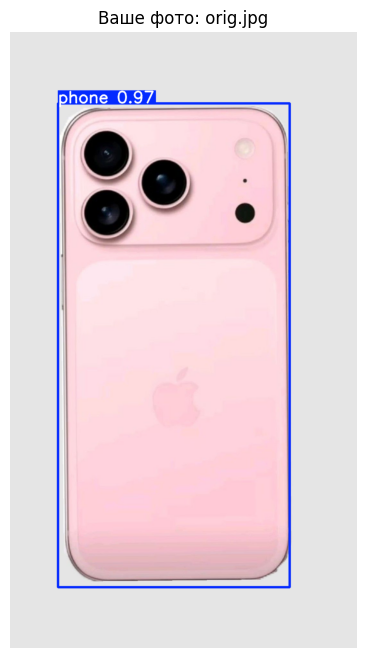

Найдено объектов: 1
  Объект: phone
  Координаты: [149.26, 222.45, 870.54, 1730.66]
  Уверенность: 0.97
  ------------------

>>> Обработка файла: origi.jpg

image 1/1 /content/origi.jpg: 448x640 2 phones, 10.5ms
Speed: 2.8ms preprocess, 10.5ms inference, 1.3ms postprocess per image at shape (1, 3, 448, 640)


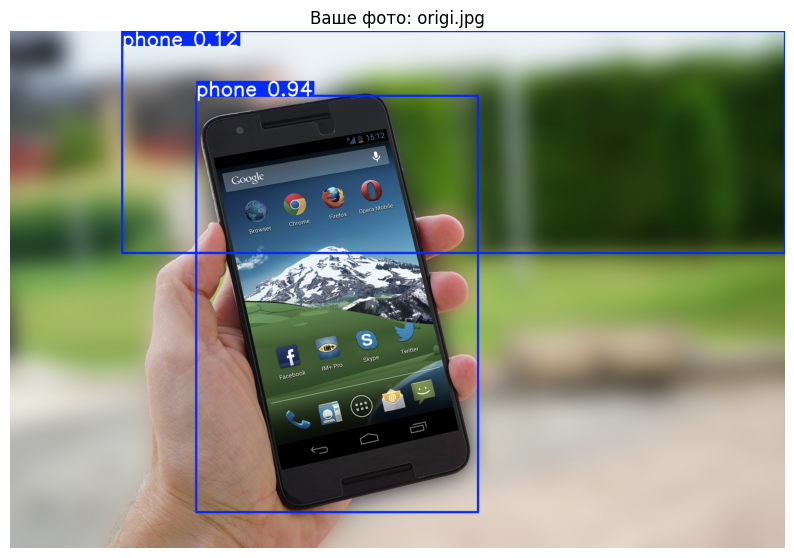

Найдено объектов: 2
  Объект: phone
  Координаты: [1441.35, 501.65, 3623.54, 3722.23]
  Уверенность: 0.94
  ------------------
  Объект: phone
  Координаты: [868.79, 0.0, 6000.0, 1717.51]
  Уверенность: 0.12
  ------------------


In [31]:
user_images = glob.glob('orig.jpg') + glob.glob("origi.jpg")

# Убираем дубликаты, если есть
user_images = list(set(user_images))

if not user_images:
    print("Личные фото не найдены. Убедитесь, что файлы лежат в корневой папке /content/")
    print("Доступные файлы в папке:", os.listdir('.'))
else:
    print(f"Найдено {len(user_images)} ваших фото для теста: {user_images}")

    # Проходимся по каждому найденному файлу
    for img_path in user_images:
        print(f"\n>>> Обработка файла: {img_path}")

        try:
            # Предсказание с низким порогом уверенности (0.1)
            results_user = best_model(img_path, conf=0.1)
            res_user = results_user[0]

            # Визуализация
            plotted_user = res_user.plot()
            plotted_user_rgb = cv2.cvtColor(plotted_user, cv2.COLOR_BGR2RGB)

            plt.figure(figsize=(10, 8))
            plt.imshow(plotted_user_rgb)
            plt.title(f"Ваше фото: {img_path}")
            plt.axis('off')
            plt.show()

            # Вывод деталей
            if len(res_user.boxes) > 0:
                print(f"Найдено объектов: {len(res_user.boxes)}")
                for box in res_user.boxes:
                    cid = int(box.cls[0].item())
                    cname = res_user.names[cid]
                    crds = [round(x, 2) for x in box.xyxy[0].tolist()]
                    conf_val = round(box.conf[0].item(), 2)

                    # Фильтруем только телефоны (если модель нашла что-то еще, например человека)
                    if cname == 'phone':
                        print(f"  Объект: {cname}")
                        print(f"  Координаты: {crds}")
                        print(f"  Уверенность: {conf_val}")
                        print("  ------------------")
            else:
                print("Объекты не обнаружены.")

        except Exception as e:
            print(f"Ошибка при обработке {img_path}: {e}")